In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [107]:
df_student_scores = pd.read_csv('/content/sample_data/studentscores.csv')

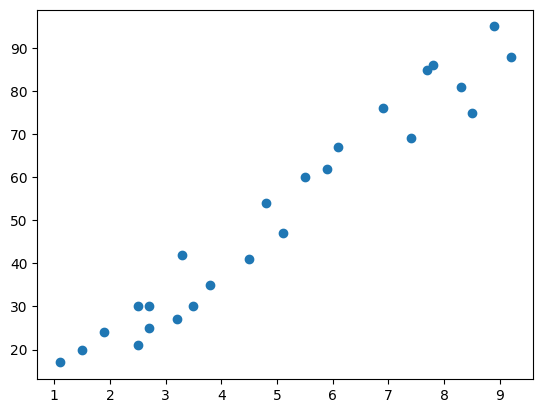

In [108]:
plt.scatter(df_student_scores['Hours'], df_student_scores['Scores'])
plt.show()

In [109]:
X=df_student_scores.iloc[:,:-1].values
Y=df_student_scores.iloc[:,1].values
print(X)
print(Y)

[[2.5]
 [5.1]
 [3.2]
 [8.5]
 [3.5]
 [1.5]
 [9.2]
 [5.5]
 [8.3]
 [2.7]
 [7.7]
 [5.9]
 [4.5]
 [3.3]
 [1.1]
 [8.9]
 [2.5]
 [1.9]
 [6.1]
 [7.4]
 [2.7]
 [4.8]
 [3.8]
 [6.9]
 [7.8]]
[21 47 27 75 30 20 88 60 81 25 85 62 41 42 17 95 30 24 67 69 30 54 35 76
 86]


In [110]:
import numpy as np

class Model():
    def __init__(self, learning_rate, iterations):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.slope = None
        self.const = None

    def predict(self, X):
        return X.dot(self.slope) + self.const

    def fit(self, X, Y):
        self.m, self.n = X.shape
        self.slope = np.zeros(self.n)
        self.const = 0
        self.X = X
        self.Y = Y

        for i in range(self.iterations):
            self.update_weights()
        return self

    def update_weights(self):
        Y_pred = self.predict(self.X)

        # Corrected gradients (removed the leading negative sign)
        dW = (2 * (self.X.T).dot(Y_pred - self.Y)) / self.m
        db = 2 * np.sum(Y_pred - self.Y) / self.m

        # Update weights by moving opposite to the gradient direction
        self.slope = self.slope - self.learning_rate * dW
        self.const = self.const - self.learning_rate * db
        return self

In [111]:
model = Model(learning_rate=0.01, iterations=1000)
model.fit(X, Y)

In [112]:
Y_pred = model.predict(X)
print(Y_pred)

[26.91 52.34 33.76 85.59 36.69 17.13 92.43 56.25 83.63 28.87 77.76 60.16
 46.47 34.73 13.22 89.5  26.91 21.04 62.12 74.83 28.87 49.4  39.62 69.94
 78.74]


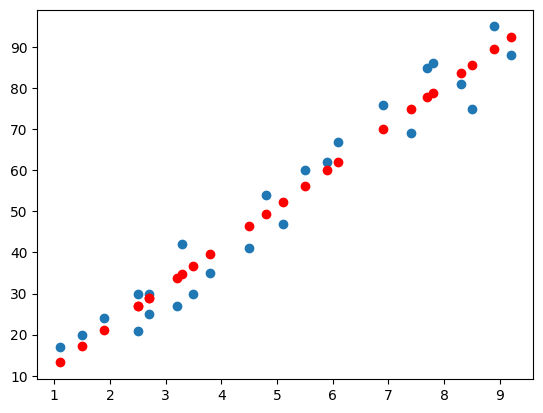

In [113]:
plt.scatter(df_student_scores['Hours'], df_student_scores['Scores'])
plt.scatter(X, Y_pred, color='red')
plt.show()

In [114]:
print(model.slope, model.const)

[9.78] 2.4644522714760995


In [115]:
import matplotlib.axes as ax
from matplotlib.animation import FuncAnimation

class LinearRegressionModel:
    def __init__(self):
        self.parameters = {}

    def forward_propagation(self, train_input):
        m = self.parameters['m']
        c = self.parameters['c']
        # Flatten train_input to 1D to match the 1D target output shape and avoid broadcasting issues
        predictions = np.multiply(m, train_input.ravel()) + c
        return predictions

    def cost_function(self, predictions, train_output):
        cost = np.mean((train_output.ravel() - predictions) ** 2)
        return cost

    def backward_propagation(self, train_input, train_output, predictions):
        derivatives = {}
        # Ensure both are 1D arrays for element-wise subtraction
        df = (predictions - train_output.ravel())
        dm = 2 * np.mean(np.multiply(train_input.ravel(), df))
        dc = 2 * np.mean(df)
        derivatives['dm'] = dm
        derivatives['dc'] = dc
        return derivatives

    def update_parameters(self, derivatives, learning_rate):
        self.parameters['m'] = self.parameters['m'] - learning_rate * derivatives['dm']
        self.parameters['c'] = self.parameters['c'] - learning_rate * derivatives['dc']

    def train(self, train_input, train_output, learning_rate, iters):
        self.parameters['m'] = np.random.uniform(0, 1) * -1
        self.parameters['c'] = np.random.uniform(0, 1) * -1

        self.loss = []

        fig, ax = plt.subplots()
        x_vals = np.linspace(min(train_input.ravel()), max(train_input.ravel()), 100)
        line, = ax.plot(x_vals, self.parameters['m'] * x_vals + self.parameters['c'], color='red', label='Regression Line')
        ax.scatter(train_input.ravel(), train_output.ravel(), marker='o', color='green', label='Training Data')

        ax.set_ylim(0, max(train_output.ravel()) + 1)

        def update(frame):
            predictions = self.forward_propagation(train_input)
            cost = self.cost_function(predictions, train_output)
            derivatives = self.backward_propagation(train_input, train_output, predictions)
            self.update_parameters(derivatives, learning_rate)
            line.set_ydata(self.parameters['m'] * x_vals + self.parameters['c'])
            self.loss.append(cost)
            print("Iteration = {}, Loss = {}".format(frame + 1, cost))
            return line,

        ani = FuncAnimation(fig, update, frames=iters, interval=200, blit=True)
        ani.save('linear_regression_a.gif', writer='ffmpeg')

        plt.xlabel('Input')
        plt.ylabel('Output')
        plt.title('Linear Regression')
        plt.legend()
        plt.show()

        return self.parameters, self.loss

Iteration = 1, Loss = 3302.5271544679913
Iteration = 1, Loss = 450.9789337669993
Iteration = 1, Loss = 83.4759280546744
Iteration = 1, Loss = 36.11143507562319
Iteration = 2, Loss = 30.005728827215606
Iteration = 3, Loss = 29.217379091394868
Iteration = 4, Loss = 29.11433015948835
Iteration = 5, Loss = 29.099612389188042
Iteration = 6, Loss = 29.096289509523604
Iteration = 7, Loss = 29.094446052826324
Iteration = 8, Loss = 29.092804051655268
Iteration = 9, Loss = 29.09119872198989
Iteration = 10, Loss = 29.089608745165247
Iteration = 11, Loss = 29.08803129265103
Iteration = 12, Loss = 29.08646591950424
Iteration = 13, Loss = 29.084912488586614
Iteration = 14, Loss = 29.083370903037586
Iteration = 15, Loss = 29.081841071791263
Iteration = 16, Loss = 29.080322905127687
Iteration = 17, Loss = 29.07881631409502
Iteration = 18, Loss = 29.07732121043047
Iteration = 19, Loss = 29.075837506545604
Iteration = 20, Loss = 29.07436511552
Iteration = 21, Loss = 29.07290395109602
Iteration = 22, Los

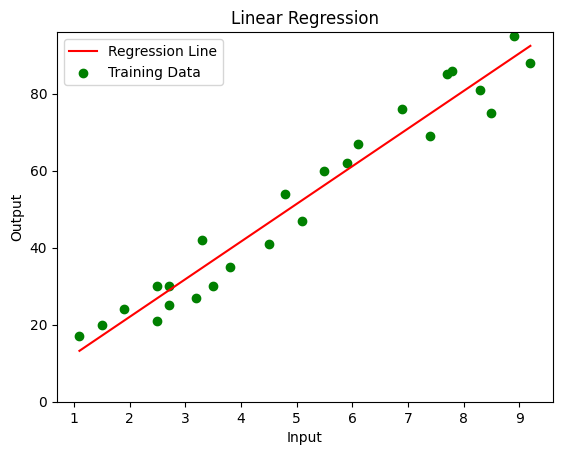

In [116]:
lin_reg_model = LinearRegressionModel()
parameters, loss = lin_reg_model.train(X, Y, learning_rate=0.01, iters=1000)

In [117]:
df_50_startups = pd.read_csv('/content/sample_data/50_Startups.csv')
X_s = df_50_startups.iloc[:, :-2].values
Y_s = df_50_startups.iloc[:, -1].values
print(X_s)
print(Y_s)

[[165349.2  136897.8  471784.1 ]
 [162597.7  151377.59 443898.53]
 [153441.51 101145.55 407934.54]
 [144372.41 118671.85 383199.62]
 [142107.34  91391.77 366168.42]
 [131876.9   99814.71 362861.36]
 [134615.46 147198.87 127716.82]
 [130298.13 145530.06 323876.68]
 [120542.52 148718.95 311613.29]
 [123334.88 108679.17 304981.62]
 [101913.08 110594.11 229160.95]
 [100671.96  91790.61 249744.55]
 [ 93863.75 127320.38 249839.44]
 [ 91992.39 135495.07 252664.93]
 [119943.24 156547.42 256512.92]
 [114523.61 122616.84 261776.23]
 [ 78013.11 121597.55 264346.06]
 [ 94657.16 145077.58 282574.31]
 [ 91749.16 114175.79 294919.57]
 [ 86419.7  153514.11      0.  ]
 [ 76253.86 113867.3  298664.47]
 [ 78389.47 153773.43 299737.29]
 [ 73994.56 122782.75 303319.26]
 [ 67532.53 105751.03 304768.73]
 [ 77044.01  99281.34 140574.81]
 [ 64664.71 139553.16 137962.62]
 [ 75328.87 144135.98 134050.07]
 [ 72107.6  127864.55 353183.81]
 [ 66051.52 182645.56 118148.2 ]
 [ 65605.48 153032.06 107138.38]
 [ 61994.4

In [118]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()

In [119]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_s, Y_s, test_size = 0.2, random_state = 0)

In [120]:
regressor.fit(X_train, Y_train)

LinearRegression()

In [121]:
y_pred = regressor.predict(X_test)
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1), Y_test.reshape(len(Y_test),1)),1))

[[103901.9  103282.38]
 [132763.06 144259.4 ]
 [133567.9  146121.95]
 [ 72911.79  77798.83]
 [179627.93 191050.39]
 [115166.65 105008.31]
 [ 67113.58  81229.06]
 [ 98154.81  97483.56]
 [114756.12 110352.25]
 [169064.01 166187.94]]


In [122]:
for i, (pred, actual) in enumerate(zip(y_pred, Y_test)):
    print(f"Prediction {i + 1}: {pred}, Actual: {actual}")

Prediction 1: 103901.89696960004, Actual: 103282.38
Prediction 2: 132763.05993125628, Actual: 144259.4
Prediction 3: 133567.90370043818, Actual: 146121.95
Prediction 4: 72911.78976735754, Actual: 77798.83
Prediction 5: 179627.92567223712, Actual: 191050.39
Prediction 6: 115166.64864795282, Actual: 105008.31
Prediction 7: 67113.57690570195, Actual: 81229.06
Prediction 8: 98154.80686776247, Actual: 97483.56
Prediction 9: 114756.11555221121, Actual: 110352.25
Prediction 10: 169064.0140879458, Actual: 166187.94


In [123]:
print(regressor.coef_)
print(regressor.intercept_)

[0.78 0.03 0.03]
42989.00816508669


In [124]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 0)

In [125]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg = PolynomialFeatures(degree = 3)
X_poly = poly_reg.fit_transform(X)
#print(X_poly)

In [126]:
mode_regressor = LinearRegression()
mode_regressor.fit(X_poly, Y)

LinearRegression()

In [127]:
print(mode_regressor.coef_)
print(mode_regressor.intercept_)

[ 0.   -3.8   3.   -0.19]
19.317706990502344


In [128]:
y_pred = mode_regressor.predict(X_poly)
print(y_pred)

[25.56 52.4  31.56 85.44 34.51 19.72 88.24 57.11 84.27 27.14 79.96 61.75
 45.41 32.52 18.51 87.29 25.56 21.61 64.03 77.39 27.14 48.89 37.62 72.62
 80.76]


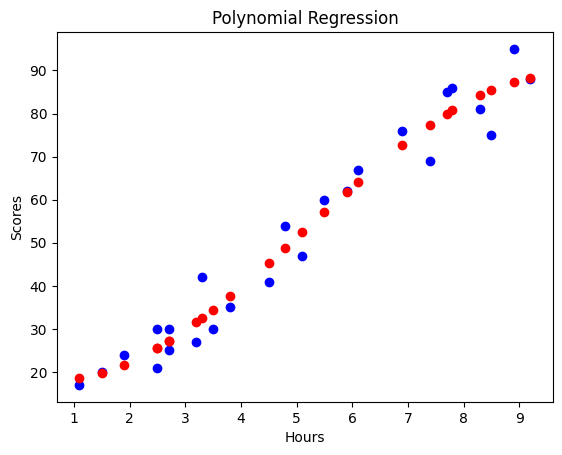

In [129]:
plt.scatter(X, Y, color = 'blue')
plt.scatter(X, y_pred, color = 'red')
plt.xlabel('Hours')
plt.ylabel('Scores')
plt.title('Polynomial Regression')
plt.show()